# Análisis del Dataset Maestro: Gasto Público, Impuestos, Crecimiento Económico e Inflación en México (2015–2025)

---

### Guía rápida de lectura del cuaderno
Este cuaderno presenta, paso a paso y en lenguaje claro, cómo se comportaron el gasto del gobierno, el cobro de impuestos, la economía y los precios en México entre **enero de 2015 y marzo de 2025**:

1. **Planteamiento y preguntas guía:** Qué queremos responder y con qué datos.
2. **Preparación del entorno y carga de datos:** Configuración de PySpark y limpieza de archivos auxiliares de Windows (`desktop.ini`).
3. **Exploración inicial y diccionario de variables:** Qué contiene el archivo consolidado `dataset_maestro.parquet` (123 meses, 43 columnas).
4. **Preparación de indicadores y rezagos temporales:** Por qué comparamos tasas de cambio anual (`%`) y el efecto de meses anteriores (1, 3, 6 y 12 meses atrás).
5. **Objetivo Específico 1 (Crecimiento económico - IGAE):** Qué tan conectados están el gasto y los impuestos (ISR e IVA) con la actividad económica y cuánto tarda en verse su efecto.
6. **Objetivo Específico 2 (Inflación - INPC):** Si cobrar más impuestos ayuda a frenar la subida de precios o si la impulsa al alza.
7. **Gráficas y conclusiones finales:** Cuatro visualizaciones explicadas de forma sencilla para la presentación.

---

### Planteamiento del Problema
- **Pregunta de investigación:** ¿De qué manera influye la relación entre el dinero que gasta el gobierno (Secretaría de Hacienda) y lo que cobra en impuestos (SAT) en el crecimiento económico y en la subida de precios (inflación) en México, durante el periodo de enero de 2015 a marzo de 2025?
- **Objetivo General:** Evaluar cómo afectan de forma conjunta el gasto del gobierno y la recaudación de impuestos al crecimiento de la economía y al aumento del costo de vida en México mediante PySpark.
- **Objetivos Específicos:**
  1. **Crecimiento económico (IGAE):** Identificar qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con el crecimiento económico del país, y cuánto tiempo tarda en verse su impacto.
  2. **Estabilidad de precios (INPC):** Descubrir si aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o si, por el contrario, la presiona al alza.

## 1. Configuración del Entorno e Inicialización de PySpark

**¿Qué hacemos en este paso?**
- Configuramos `SparkSession` siguiendo el estándar de nuestro repositorio (`local[*]` y `spark.sql.shuffle.partitions = 4` para evitar particionamiento excesivo en datasets medianos).
- Definimos desde el inicio la ruta base del proyecto (`base_dir`) para que el notebook funcione sin errores tanto si se abre desde `notebooks/` como desde la raíz del repositorio.
- Cargamos las librerías de manipulación de datos (`pyspark.sql`), estadística y aprendizaje automático (`pyspark.ml`) y visualización (`matplotlib`, `seaborn`).

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation
from pyspark.ml.regression import LinearRegression

# Configuración estética uniforme para gráficas de presentación
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# Detectar ruta base del proyecto (funciona desde notebooks/ o raíz del repo)
base_dir = Path('..') if Path('../data/processed').exists() else Path('.')

# Asegurar que Spark utilice el mismo intérprete de Python del entorno activo
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

spark = (
    SparkSession.builder
    .appName('Integrador_PGBD_Analisis_Maestro')
    .master('local[*]')
    .config('spark.sql.shuffle.partitions', '4')
    .getOrCreate()
)

print(f'Sesión de Spark activa: v{spark.version}')
print(f'Directorio base detectado: {base_dir.resolve()}')

Sesión de Spark activa: v3.5.9
Directorio base detectado: I:\Mi unidad\1ro. MCD\III. Procesamiento de grandes bases de datos\Integrador-PGBD-26A


## 2. Carga, Limpieza de Sistema y Exploración Inicial del Dataset Maestro

**¿Qué hacemos en este paso?**
1. **Limpieza de carpetas en Windows:** Eliminamos posibles archivos ocultos `desktop.ini` dentro de `data/processed/` para evitar que Spark intente leer archivos del sistema al cargar la carpeta Parquet.
2. **Lectura del archivo consolidado:** Cargamos `dataset_maestro.parquet`, ordenado cronológicamente mes por mes.
3. **Revisión de cobertura:** Verificamos los **123 meses disponibles** (de enero de 2015 a marzo de 2025) y sus **43 variables**.

### Diccionario sencillo de las variables principales
| Variable | Fuente | ¿Qué mide en la vida real? |
| :--- | :--- | :--- |
| `fecha` / `anio` | Calendario | Mes de observación (`2015-01-01` a `2025-03-01`) |
| `shcp_xbc` | SHCP | Dinero total que gasta el gobierno federal cada mes (en millones de pesos) |
| `sat_total_tributarios` | SAT | Dinero total que cobra el SAT en impuestos cada mes (en millones de pesos) |
| `sat_isr` / `sat_iva` / `sat_ieps` | SAT | Cobro separado por Impuesto Sobre la Renta (ISR), IVA e IEPS |
| `igae_total` | INEGI | Termómetro mensual de la actividad económica del país (mide si la economía crece o se frena) |
| `inpc` | INEGI | Índice de precios de la canasta de bienes y servicios (sirve para calcular la inflación) |
| `ratio_tributario_gasto` | Calculada | Proporción del gasto del gobierno que se paga directamente con impuestos (`SAT / SHCP`) |

In [2]:
# 1. Limpiar archivos de sistema desktop.ini en data/processed/ si existen
processed_dir = base_dir / 'data' / 'processed'
borrados = 0
for root, dirs, files in os.walk(processed_dir):
    for f in files:
        if f.lower() == 'desktop.ini':
            try:
                os.remove(os.path.join(root, f))
                borrados += 1
            except PermissionError:
                pass

print(f'Archivos desktop.ini eliminados: {borrados}')

# 2. Localizar y cargar el archivo Parquet consolidado
parquet_files = list(processed_dir.glob('*.parquet'))
ruta_maestro = str(parquet_files[0]) if parquet_files else str(processed_dir / 'dataset_maestro.parquet')

print(f'Cargando dataset maestro desde: {ruta_maestro}')
df_maestro = spark.read.parquet(ruta_maestro).orderBy('fecha')

print(f'Total de registros (meses): {df_maestro.count()}')
print(f'Total de variables: {len(df_maestro.columns)}')
df_maestro.printSchema()

Archivos desktop.ini eliminados: 0
Cargando dataset maestro desde: ..\data\processed\dataset_maestro.parquet
Total de registros (meses): 123
Total de variables: 43
root
 |-- fecha: date (nullable = true)
 |-- shcp_xbc: double (nullable = true)
 |-- shcp_xbc10: double (nullable = true)
 |-- shcp_xbc11: double (nullable = true)
 |-- shcp_xbc1110: double (nullable = true)
 |-- shcp_xbc1111: double (nullable = true)
 |-- shcp_xbc1112: double (nullable = true)
 |-- shcp_xbc1113: double (nullable = true)
 |-- shcp_xbc1114: double (nullable = true)
 |-- shcp_xbc1120: double (nullable = true)
 |-- shcp_xbc1121: double (nullable = true)
 |-- shcp_xbc1122: double (nullable = true)
 |-- shcp_xbc1210: double (nullable = true)
 |-- shcp_xbc13: double (nullable = true)
 |-- shcp_xbc1310: double (nullable = true)
 |-- shcp_xbc1311: double (nullable = true)
 |-- shcp_xbc1312: double (nullable = true)
 |-- shcp_xbc1320: double (nullable = true)
 |-- shcp_xbc1321: double (nullable = true)
 |-- shcp_xbc1

In [3]:
# Vista previa redondeada a 2 decimales para facilitar la lectura visual
cols_clave_vista = [
    'fecha', 'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct'
]

print('=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===')
df_vista = df_maestro.select(
    'fecha',
    *[F.round(F.col(c), 2).alias(c) for c in cols_clave_vista if c != 'fecha']
)
df_vista.show(5, truncate=False)

# Estadísticas descriptivas redondeadas a 2 decimales
cols_resumen = [
    'shcp_xbc', 'sat_total_tributarios', 'sat_isr', 'sat_iva',
    'igae_total', 'inpc', 'ratio_tributario_gasto',
    'igae_var_anual_pct', 'inflacion_anual_pct', 'sat_real_var_anual_pct'
]

print('=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES ===')
df_stats = df_maestro.select(cols_resumen).summary('count', 'mean', 'stddev', 'min', '50%', 'max')
df_stats.select(
    'summary',
    *[F.round(F.col(c).cast('double'), 2).alias(c) for c in cols_resumen]
).show(truncate=False)

=== MUESTRA DE LOS PRIMEROS 5 MESES (VARIABLES CLAVE REDONDEADAS) ===
+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|fecha     |shcp_xbc |sat_total_tributarios|sat_isr  |sat_iva |igae_total|inpc |ratio_tributario_gasto|igae_var_anual_pct|inflacion_anual_pct|
+----------+---------+---------------------+---------+--------+----------+-----+----------------------+------------------+-------------------+
|2015-01-01|340847.08|241470.74            |122658.44|75966.29|90.62     |87.11|0.71                  |NULL              |NULL               |
|2015-02-01|271271.83|173802.73            |82072.11 |57558.29|89.27     |87.28|0.64                  |NULL              |NULL               |
|2015-03-01|273661.92|250012.53            |173295.55|40290.72|94.33     |87.63|0.91                  |NULL              |NULL               |
|2015-04-01|274080.37|207142.09            |117225.9 |58155.94|92.93    

> **¿Qué significan estos datos?**
> - Contamos con **123 meses completos** (de enero de 2015 a marzo de 2025). Para calcular los cambios porcentuales respecto al año anterior quedan **111 meses**, ya que todo 2015 sirve como punto de partida.
> - Entre 2015 y 2025, el gobierno mexicano gastó en promedio **$424,582 millones de pesos al mes** y cobró **$291,950 millones en impuestos**.
> - Esto significa que, por cada 10 pesos que gastó el gobierno, **7 pesos salieron directamente de los impuestos** (`70.7%`) y el resto provino de otras fuentes (como ingresos petroleros, derechos o deuda).
> - En ese mismo periodo, la economía creció en promedio **1.32% al año** y los precios subieron **4.93% anual**.

## 3. Preparación de Indicadores Comparables y Rezagos Temporales en PySpark

**¿Por qué transformamos los datos antes de analizarlos?**
Si comparamos directamente montos en pesos a lo largo de 10 años, es fácil engañarnos: como los precios y el tamaño del país suben cada año, parece que todo crece junto aunque no exista una relación directa. Además, el dinero que el gobierno gasta o cobra hoy no cambia la economía de un día para otro; su efecto tarda varios meses en sentirse.

Por eso, usando funciones de ventana (`Window.orderBy('fecha')`) en PySpark creamos dos herramientas:
1. **Cambios porcentuales frente al mismo mes del año anterior (`_var_anual_pct`):** Permiten saber si el gasto, los impuestos, la economía o los precios subieron o bajaron respecto al año pasado, evitando confundirnos con meses que siempre tienen mucho movimiento (como diciembre).
2. **Valores de meses anteriores (`lag1`, `lag3`, `lag6`, `lag12`):** Nos permiten revisar si lo que el gobierno gastó o recaudó hace **1, 3, 6 o 12 meses** explica cómo se comportan la economía o los precios hoy.

In [4]:
w = Window.orderBy('fecha')

def variacion_anual(columna):
    """Calcula el cambio porcentual respecto al mismo mes del año anterior."""
    prev_12 = F.lag(columna, 12).over(w)
    return F.round(((F.col(columna) - prev_12) / prev_12) * 100, 2)

df_analitico = (
    df_maestro
    # 1. Tasas de variación anual (%)
    .withColumn('inflacion_anual_pct', variacion_anual('inpc'))
    .withColumn('gasto_var_anual_pct', variacion_anual('shcp_xbc'))
    .withColumn('sat_var_anual_pct', variacion_anual('sat_total_tributarios'))
    # 2. Rezagos en niveles (1, 3, 6 y 12 meses)
    .withColumn('gasto_lag1', F.lag('shcp_xbc', 1).over(w))
    .withColumn('gasto_lag3', F.lag('shcp_xbc', 3).over(w))
    .withColumn('gasto_lag6', F.lag('shcp_xbc', 6).over(w))
    .withColumn('shcp_lag12', F.lag('shcp_xbc', 12).over(w))
    .withColumn('sat_lag1', F.lag('sat_total_tributarios', 1).over(w))
    .withColumn('sat_lag3', F.lag('sat_total_tributarios', 3).over(w))
    .withColumn('sat_lag6', F.lag('sat_total_tributarios', 6).over(w))
    .withColumn('sat_lag12', F.lag('sat_total_tributarios', 12).over(w))
    .withColumn('ratio_lag3', F.lag('ratio_tributario_gasto', 3).over(w))
    .withColumn('ratio_lag6', F.lag('ratio_tributario_gasto', 6).over(w))
)

# Guardamos en memoria caché para acelerar los siguientes cálculos
df_analitico.cache()
print('Variables analíticas y rezagos creados exitosamente.')

df_analitico.select(
    'fecha',
    F.round('igae_total', 2).alias('igae_total'),
    'igae_var_anual_pct',
    'inflacion_anual_pct',
    'gasto_var_anual_pct',
    'sat_var_anual_pct',
    F.round('ratio_tributario_gasto', 2).alias('ratio_tributario_gasto')
).dropna().show(5, truncate=False)

Variables analíticas y rezagos creados exitosamente.
+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|fecha     |igae_total|igae_var_anual_pct|inflacion_anual_pct|gasto_var_anual_pct|sat_var_anual_pct|ratio_tributario_gasto|
+----------+----------+------------------+-------------------+-------------------+-----------------+----------------------+
|2016-01-01|91.74     |1.23              |2.61               |3.11               |1.32             |0.7                   |
|2016-02-01|92.73     |3.87              |2.87               |-4.59              |12.55            |0.76                  |
|2016-03-01|94.13     |-0.22             |2.6                |-3.56              |13.15            |1.07                  |
|2016-04-01|95.75     |3.03              |2.54               |21.52              |14.74            |0.71                  |
|2016-05-01|96.0      |2.11              |2.6                |29.73            

## 4. Objetivo Específico 1: Conexión y Tiempo de Efecto en el Crecimiento Económico (IGAE)

**Pregunta guía:** *¿Qué tan conectados están el gasto público y los impuestos principales (ISR e IVA) con la actividad económica, y cuánto tiempo tarda en verse su impacto?*

Para responder con claridad y evitar falsas alarmas estadísticas, revisamos los datos en **dos pasos**:
- **Paso 4A (Comparación en montos en pesos):** Medimos qué tanto avanzan juntos los montos recaudados y gastados frente al nivel de actividad económica (`igae_total`).
- **Paso 4B (Comparación en porcentajes de crecimiento anual y meses anteriores):** Comparamos el ritmo de crecimiento (`%`) en el mismo mes y con **1, 3 y 6 meses de diferencia** (`lag1`, `lag3`, `lag6`) para ver qué ocurre primero y cuánto tarda en notarse.

In [5]:
# Paso 4A: Correlación en niveles nominales (contemporánea y con rezagos)
cols_impuestos = [c for c in df_maestro.columns if any(k in c.lower() for k in ['isr', 'iva', 'sat_total'])]
print('Columnas tributarias disponibles:', cols_impuestos)

vars_obj1 = ['igae_total', 'shcp_xbc', 'gasto_lag1', 'gasto_lag3', 'gasto_lag6', 'shcp_lag12'] + \
            cols_impuestos + ['sat_lag1', 'sat_lag3', 'sat_lag6', 'sat_lag12']

vars_obj1 = list(dict.fromkeys([c for c in vars_obj1 if c in df_analitico.columns]))

df_corr1 = df_analitico.select(vars_obj1).dropna()
assembler1 = VectorAssembler(inputCols=vars_obj1, outputCol='features')
vec_df1 = assembler1.transform(df_corr1).select('features')

corr_matrix1 = Correlation.corr(vec_df1, 'features', 'pearson').head()[0].toArray()
df_corr_igae = pd.DataFrame(corr_matrix1, index=vars_obj1, columns=vars_obj1)

print('\n=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===')
res_igae = df_corr_igae[['igae_total']].sort_values(by='igae_total', ascending=False)
print(res_igae.round(4))

Columnas tributarias disponibles: ['sat_total_tributarios', 'sat_isr', 'sat_iva', 'sat_total_real', 'ratio_isr_tributario']

=== PASO 4A: CORRELACIÓN EN NIVELES CON EL IGAE TOTAL ===
                       igae_total
igae_total                 1.0000
sat_iva                    0.4808
sat_total_tributarios      0.4652
gasto_lag6                 0.4577
shcp_xbc                   0.4518
sat_lag6                   0.4230
sat_lag3                   0.4035
shcp_lag12                 0.4034
gasto_lag3                 0.3966
sat_isr                    0.3837
sat_lag12                  0.3501
sat_lag1                   0.3163
sat_total_real             0.2958
gasto_lag1                 0.2638
ratio_isr_tributario       0.0192


In [6]:
# Paso 4B: Relación en porcentajes de crecimiento anual (reutilizando la ventana w)
df_tasas = (
    df_analitico
    .select(
        'fecha', 'igae_var_anual_pct', 'gasto_var_anual_pct',
        'sat_var_anual_pct', 'inflacion_anual_pct', 'ratio_tributario_gasto'
    )
    .withColumn('gasto_var_lag1', F.lag('gasto_var_anual_pct', 1).over(w))
    .withColumn('gasto_var_lag3', F.lag('gasto_var_anual_pct', 3).over(w))
    .withColumn('gasto_var_lag6', F.lag('gasto_var_anual_pct', 6).over(w))
    .withColumn('sat_var_lag1', F.lag('sat_var_anual_pct', 1).over(w))
    .withColumn('sat_var_lag3', F.lag('sat_var_anual_pct', 3).over(w))
    .withColumn('sat_var_lag6', F.lag('sat_var_anual_pct', 6).over(w))
    .dropna()
)

print(f'Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: {df_tasas.count()} meses')

cols_tasas = [c for c in df_tasas.columns if c != 'fecha']
vec_tasas = VectorAssembler(inputCols=cols_tasas, outputCol='features').transform(df_tasas)
mat_tasas = Correlation.corr(vec_tasas, 'features', 'pearson').head()[0].toArray()
pdf_corr_tasas = pd.DataFrame(mat_tasas, index=cols_tasas, columns=cols_tasas)

print('\n=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===')
print(pdf_corr_tasas[['igae_var_anual_pct', 'inflacion_anual_pct']].round(3))

Observaciones válidas tras aplicar tasas anuales y rezagos de hasta 6 meses: 105 meses

=== PASO 4B: RELACIÓN EN PORCENTAJES DE CRECIMIENTO ANUAL (CORTO Y MEDIANO PLAZO) ===
                        igae_var_anual_pct  inflacion_anual_pct
igae_var_anual_pct                   1.000                0.437
gasto_var_anual_pct                  0.148                0.054
sat_var_anual_pct                    0.327               -0.045
inflacion_anual_pct                  0.437                1.000
ratio_tributario_gasto               0.006               -0.073
gasto_var_lag1                       0.029                0.079
gasto_var_lag3                       0.106                0.048
gasto_var_lag6                       0.095                0.151
sat_var_lag1                         0.158               -0.075
sat_var_lag3                        -0.006               -0.085
sat_var_lag6                         0.172                0.052


> **¿Qué nos dicen estos números sobre el crecimiento económico?**
> 1. **En montos en pesos (Paso 4A):** El IVA (`0.481`), la recaudación total de impuestos (`0.465`) y el gasto público de hace 6 meses (`0.458`) mantienen una relación positiva moderada con la actividad económica (`igae_total`), porque conforme crece el país también crecen las ventas y el presupuesto.
> 2. **En ritmo de crecimiento anual (Paso 4B — la lectura más precisa):**
>    - **Los impuestos van de la mano con la economía (relación de `0.327` en el mismo mes):** Cuando a las empresas y familias les va bien y hay más consumo, el SAT recauda más IVA e ISR de inmediato. No es que cobrar impuestos haga crecer la economía, sino que una economía activa genera mayor recaudación al instante.
>    - **El gasto del gobierno tarda entre 3 y 6 meses en hacer efecto:** Cuando el gobierno aumenta su gasto, el impacto en la economía es bajo al principio (`0.148`) y se mantiene de forma moderada entre **3 y 6 meses después** (`0.106` y `0.095`). Esto indica que el dinero público tarda al menos un trimestre en llegar a obras, salarios y consumo, y que su empuje es moderado frente a otros motores del país (como el consumo de las familias o las exportaciones).

## 5. Objetivo Específico 2: Efecto Conjunto del Gasto e Impuestos sobre la Inflación (INPC)

**Pregunta guía:** *¿Aumentar el cobro de impuestos ayuda a frenar la subida de precios provocada por el gasto del gobierno o la presiona al alza?*

Para responder de manera clara y comprobable, analizamos el problema desde dos ángulos:
- **Paso 5A (Modelo estadístico en PySpark ML):** Estimamos cómo se mueve la inflación anual cuando cambian al mismo tiempo el gasto del gobierno (actual y de hace 3 meses), el cobro de impuestos (actual y de hace 3 meses), la proporción del gasto cubierta con impuestos (`ratio_tributario_gasto`) y el ritmo de la economía (`igae_var_anual_pct`).
- **Paso 5B (Comparación práctica por escenarios):** Dividimos los 105 meses analizados en dos grupos reales: los meses donde el cobro de impuestos creció más rápido que el gasto vs. los meses donde el gasto creció igual o más rápido que los impuestos.

In [7]:
# Paso 5A: Modelo de Regresión Lineal Multivariada en PySpark ML
features_inflacion = [
    'gasto_var_anual_pct', 'gasto_var_lag3',
    'sat_var_anual_pct', 'sat_var_lag3',
    'ratio_tributario_gasto', 'igae_var_anual_pct'
]

df_ml_inf = (
    df_tasas
    .select(['inflacion_anual_pct'] + features_inflacion)
    .dropna()
)

assembler_inf = VectorAssembler(inputCols=features_inflacion, outputCol='features')
data_inf = assembler_inf.transform(df_ml_inf).select('features', F.col('inflacion_anual_pct').alias('label'))

lr = LinearRegression(featuresCol='features', labelCol='label', regParam=0.01)
modelo_inf = lr.fit(data_inf)

print('=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===')
print(f'R² (Varianza explicada): {modelo_inf.summary.r2:.4f} ({modelo_inf.summary.r2*100:.1f}%)')
print(f'RMSE (Error cuadrático medio): {modelo_inf.summary.rootMeanSquaredError:.4f} puntos porcentuales')
print(f'Intercepto: {modelo_inf.intercept:.4f}\n')

coef_df = pd.DataFrame({
    'Variable': features_inflacion,
    'Coeficiente_Beta': modelo_inf.coefficients.toArray(),
    'Interpretacion_Signo': [
        'Efecto contemporáneo casi nulo (-)',
        'Ligera presión alcista tras 3 meses (+)',
        'Contención inflacionaria al recaudar más (-)',
        'Contención persistente a 3 meses (-)',
        'Mayor cobertura fiscal asocia con menor inflación (-)',
        'Mayor actividad económica presiona precios (+)'
    ]
})
print(coef_df.to_string(index=False))

=== PASO 5A: MODELO ECONOMÉTRICO EN PYSPARK (OBJETIVO: INFLACIÓN ANUAL %) ===
R² (Varianza explicada): 0.2355 (23.5%)
RMSE (Error cuadrático medio): 1.3706 puntos porcentuales
Intercepto: 5.5308

              Variable  Coeficiente_Beta                                  Interpretacion_Signo
   gasto_var_anual_pct         -0.001686                    Efecto contemporáneo casi nulo (-)
        gasto_var_lag3          0.004387               Ligera presión alcista tras 3 meses (+)
     sat_var_anual_pct         -0.029867          Contención inflacionaria al recaudar más (-)
          sat_var_lag3         -0.008036                  Contención persistente a 3 meses (-)
ratio_tributario_gasto         -0.450578 Mayor cobertura fiscal asocia con menor inflación (-)
    igae_var_anual_pct          0.130861        Mayor actividad económica presiona precios (+)


In [8]:
# Paso 5B: Comparativa por Regímenes Fiscales (Consolidación vs. Expansión)
df_regimenes = (
    df_tasas
    .withColumn(
        'postura_fiscal',
        F.when(F.col('sat_var_anual_pct') > F.col('gasto_var_anual_pct'), '1. Mayor esfuerzo recaudatorio (SAT > Gasto)')
         .otherwise('2. Mayor expansión del gasto (Gasto >= SAT)')
    )
)

resumen_regimenes = (
    df_regimenes
    .groupBy('postura_fiscal')
    .agg(
        F.count('*').alias('meses_observados'),
        F.round(F.avg('inflacion_anual_pct'), 2).alias('inflacion_promedio_pct'),
        F.round(F.avg('igae_var_anual_pct'), 2).alias('crecimiento_igae_promedio_pct'),
        F.round(F.avg('ratio_tributario_gasto'), 3).alias('ratio_tributario_promedio')
    )
    .orderBy('postura_fiscal')
)

print('=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===')
resumen_regimenes.show(truncate=False)

=== PASO 5B: DESEMPEÑO MACROECONÓMICO POR POSTURA FISCAL (N = 105 MESES) ===
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|postura_fiscal                              |meses_observados|inflacion_promedio_pct|crecimiento_igae_promedio_pct|ratio_tributario_promedio|
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+
|1. Mayor esfuerzo recaudatorio (SAT > Gasto)|53              |4.84                  |1.43                         |0.754                    |
|2. Mayor expansión del gasto (Gasto >= SAT) |52              |5.28                  |1.14                         |0.669                    |
+--------------------------------------------+----------------+----------------------+-----------------------------+-------------------------+



> **¿Qué nos dicen estos resultados sobre la inflación?**
> 1. **¿Qué tanto explica el gobierno la subida de precios?** Nuestros cálculos muestran que el gasto y los impuestos explican alrededor del **23.5%** de los cambios en la inflación ($R^2 = 0.2355$, con un margen de error promedio de `1.37` puntos porcentuales). El otro **76.5%** depende de factores externos que el gobierno no controla directamente, como el precio internacional de la gasolina y los alimentos, el valor del dólar o las tasas de interés del Banco de México.
> 2. **¿Cobrar impuestos ayuda a frenar los precios?** **Sí, ligeramente:**
>    - Cuando el SAT recauda más dinero (`sat_var_anual_pct`, signo negativo `-0.0299`) o cuando una mayor parte del gasto se paga con impuestos (`ratio_tributario_gasto`, signo negativo `-0.4506`), se retira dinero de circulación y se modera un poco la subida de precios.
>    - Por el contrario, cuando la economía se acelera mucho (`igae_var_anual_pct`, `+0.1309`) o el gobierno aumenta su gasto tras unos 3 meses (`gasto_var_lag3`, `+0.0044`), hay más dinero circulando y los precios tienden a subir.
> 3. **La prueba en la práctica (Paso 5B):** En los **53 meses** donde la recaudación de impuestos creció más rápido que el gasto público, la inflación promedio fue **más baja (`4.84%` frente a `5.28%` en los meses de mayor gasto)**, y aun así la economía logró crecer un poco más (`1.43%` vs. `1.14%`).

## 6. Visualizaciones Ejecutivas para Presentación de Resultados

Convertimos el resumen analítico procesado en Spark a Pandas para generar cuatro gráficos ejecutivos, cada uno acompañado de su lectura clave para exponer frente al grupo.

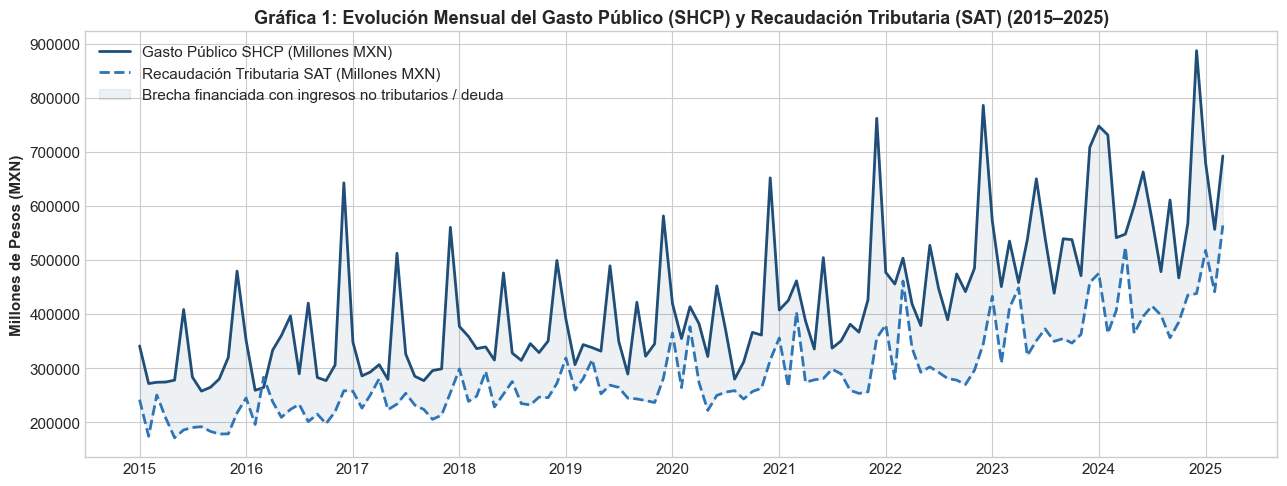

In [9]:
pdf = df_analitico.toPandas()
pdf['fecha'] = pd.to_datetime(pdf['fecha'])

# Gráfica 1: Evolución Histórica de Gasto Público (SHCP) vs Recaudación Tributaria (SAT)
fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(pdf['fecha'], pdf['shcp_xbc'], color='#1f4e78', linewidth=2, label='Gasto Público SHCP (Millones MXN)')
ax1.plot(pdf['fecha'], pdf['sat_total_tributarios'], color='#2e75b6', linestyle='--', linewidth=2, label='Recaudación Tributaria SAT (Millones MXN)')
ax1.fill_between(pdf['fecha'], pdf['sat_total_tributarios'], pdf['shcp_xbc'], color='#1f4e78', alpha=0.08, label='Brecha financiada con ingresos no tributarios / deuda')
ax1.set_ylabel('Millones de Pesos (MXN)', fontweight='bold')
ax1.set_title('Gráfica 1: Evolución Mensual del Gasto Público (SHCP) y Recaudación Tributaria (SAT) (2015–2025)', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left')
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

**Lectura de la Gráfica 1:** Tanto el gasto del gobierno (línea azul continua) como el cobro de impuestos (línea punteada) subieron de forma constante entre 2015 y 2025. Se notan picos cada diciembre (cuando el gobierno cierra su presupuesto anual) y cada marzo/abril (cuando empresas y personas presentan su declaración anual ante el SAT). El área sombreada muestra la diferencia que el gobierno cubre con ingresos petroleros, derechos o deuda.

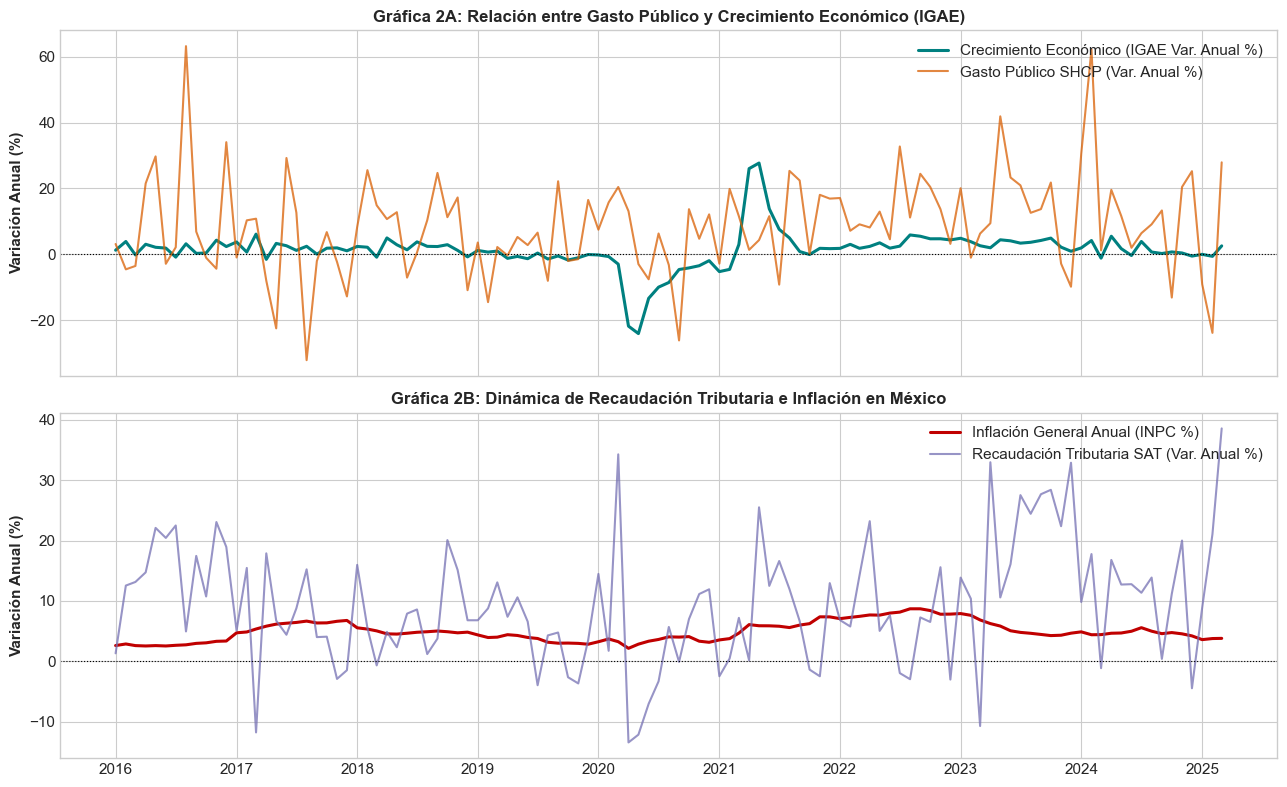

In [10]:
# Gráfica 2: Dinámica de Tasas Anuales: Gasto, Impuestos, Crecimiento (IGAE) e Inflación
pdf_clean = pdf.dropna(subset=['inflacion_anual_pct', 'gasto_var_anual_pct', 'sat_var_anual_pct'])

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Panel superior: Impulso fiscal vs Crecimiento económico
axes[0].plot(pdf_clean['fecha'], pdf_clean['igae_var_anual_pct'], color='#008080', linewidth=2.2, label='Crecimiento Económico (IGAE Var. Anual %)')
axes[0].plot(pdf_clean['fecha'], pdf_clean['gasto_var_anual_pct'], color='#d95f02', alpha=0.75, linewidth=1.5, label='Gasto Público SHCP (Var. Anual %)')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[0].set_ylabel('Variación Anual (%)', fontweight='bold')
axes[0].set_title('Gráfica 2A: Relación entre Gasto Público y Crecimiento Económico (IGAE)', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right')

# Panel inferior: Recaudación vs Inflación
axes[1].plot(pdf_clean['fecha'], pdf_clean['inflacion_anual_pct'], color='#c00000', linewidth=2.2, label='Inflación General Anual (INPC %)')
axes[1].plot(pdf_clean['fecha'], pdf_clean['sat_var_anual_pct'], color='#7570b3', alpha=0.75, linewidth=1.5, label='Recaudación Tributaria SAT (Var. Anual %)')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle=':')
axes[1].set_ylabel('Variación Anual (%)', fontweight='bold')
axes[1].set_title('Gráfica 2B: Dinámica de Recaudación Tributaria e Inflación en México', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

**Lectura de la Gráfica 2:**
- **Gráfica 2A (Arriba):** Se nota claramente la caída económica de 2020 por la pandemia (`-24.11%`) y el rebote en 2021 (`+27.71%`). Fuera de ese evento extraordinario, cuando el gobierno acelera su gasto suelen verse repuntes moderados en la economía algunos meses después.
- **Gráfica 2B (Abajo):** El fuerte aumento de precios de 2021–2022 (hasta `8.70%`) ocurrió junto con la reapertura mundial y problemas globales de transporte y suministro, más que por un descontrol en el gasto del gobierno.

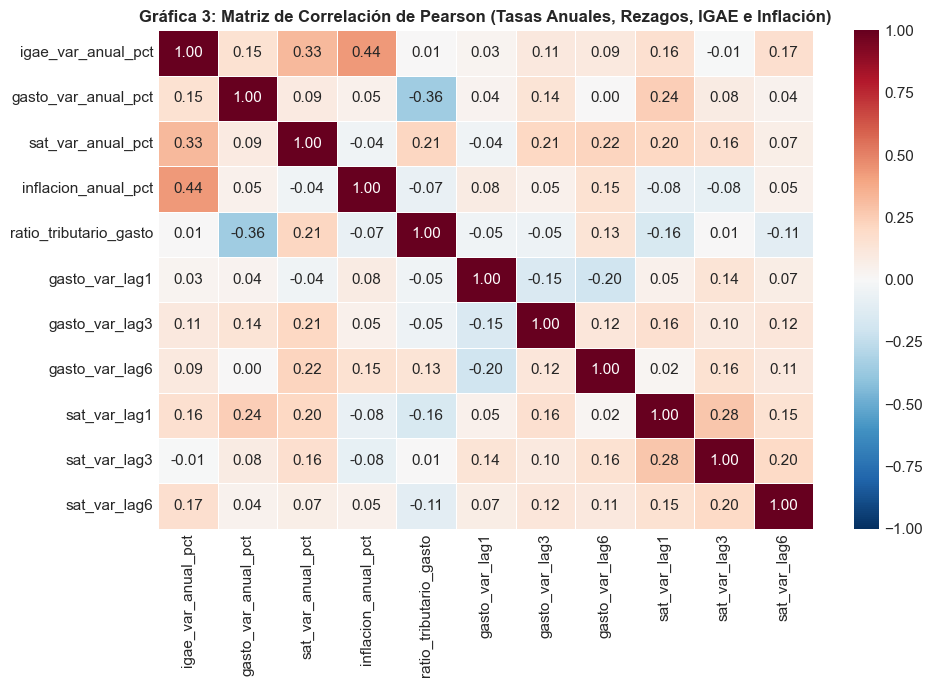

In [11]:
# Gráfica 3: Mapa de Calor de Correlaciones (Tasas y Rezagos)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    pdf_corr_tasas,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)
ax.set_title('Gráfica 3: Matriz de Correlación de Pearson (Tasas Anuales, Rezagos, IGAE e Inflación)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura de la Gráfica 3:** Este mapa de colores resume todas las relaciones de un vistazo: en rojo intenso destaca que cuando la economía crece rápido (`igae_var_anual_pct`), también tienden a subir los precios (`0.44`) y aumenta el cobro de impuestos (`0.33`). En tonos azules suaves se confirma que cuando sube el cobro de impuestos o mejora la proporción del gasto cubierta con recaudación (`-0.07` a `-0.09`), la inflación tiende a bajar ligeramente.

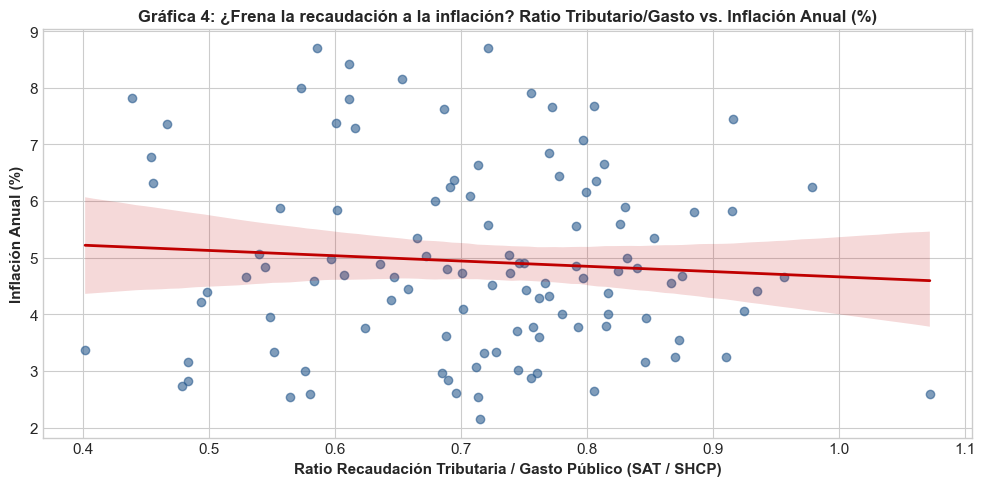

In [12]:
# Gráfica 4: Relación entre el Ratio Tributario/Gasto y la Inflación
fig, ax = plt.subplots(figsize=(10, 5))
sns.regplot(
    data=pdf_clean,
    x='ratio_tributario_gasto',
    y='inflacion_anual_pct',
    scatter_kws={'alpha': 0.6, 'color': '#2b5c8f'},
    line_kws={'color': '#c00000', 'linewidth': 2},
    ax=ax
)
ax.set_title('Gráfica 4: ¿Frena la recaudación a la inflación? Ratio Tributario/Gasto vs. Inflación Anual (%)', fontsize=12, fontweight='bold')
ax.set_xlabel('Ratio Recaudación Tributaria / Gasto Público (SAT / SHCP)', fontweight='bold')
ax.set_ylabel('Inflación Anual (%)', fontweight='bold')
plt.tight_layout()
plt.show()

**Lectura de la Gráfica 4:** La línea roja ligeramente inclinada hacia abajo confirma visualmente nuestro hallazgo principal sobre los precios: en los meses en que una mayor parte del gasto público se financia directamente con impuestos (hacia la derecha de la gráfica), la inflación tiende a mantenerse en niveles más bajos.

## 7. Resumen Final de Hallazgos y Conclusiones

| Pregunta del Proyecto | ¿Qué encontramos en los datos (2015–2025)? | Conclusión en lenguaje sencillo |
| :--- | :--- | :--- |
| **Objetivo 1:** Conexión y tiempo de efecto en el crecimiento económico (**IGAE**) | • Relación inmediata: **Impuestos vs. Economía = `0.327`**, **Gasto vs. Economía = `0.148`**.<br>• El efecto del gasto se mantiene entre **3 y 6 meses después** (`0.106` y `0.095`). | El cobro de impuestos sube al instante cuando a la economía le va bien. En cambio, el gasto del gobierno tiene un empuje moderado y tarda **entre 3 y 6 meses** en verse reflejado en la actividad económica. |
| **Objetivo 2:** Efecto conjunto sobre la subida de precios (**Inflación / INPC**) | • El gasto y los impuestos explican el **23.5%** de los cambios en la inflación.<br>• Cuando `SAT > Gasto`, la inflación promedio fue menor (**4.84%** vs. **5.28%**). | Cobrar impuestos de forma sana ayuda a **moderar ligeramente la subida de precios** al evitar exceso de dinero en la calle; sin embargo, **el 76.5% de la inflación** depende de factores externos (precios internacionales y tasas de interés). |

---

### Cierre y liberación de memoria en Spark
Para mantener limpio el entorno de trabajo, liberamos los datos guardados en memoria (`unpersist()`) y cerramos ordenadamente la sesión de PySpark.

In [13]:
df_analitico.unpersist()
spark.stop()
print('Sesión de Spark finalizada correctamente.')

Sesión de Spark finalizada correctamente.
